In [2]:
import pandas as pd, numpy as np
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.metrics import mean_squared_error

In [3]:
df = pd.read_csv(r"C:\Users\Harini.S\Downloads\Walmart_Sales.csv")
print(df.head())
print(df.columns)

   Store        Date  Weekly_Sales  Holiday_Flag  Temperature  Fuel_Price  \
0      1  05-02-2010    1643690.90             0        42.31       2.572   
1      1  12-02-2010    1641957.44             1        38.51       2.548   
2      1  19-02-2010    1611968.17             0        39.93       2.514   
3      1  26-02-2010    1409727.59             0        46.63       2.561   
4      1  05-03-2010    1554806.68             0        46.50       2.625   

          CPI  Unemployment  
0  211.096358         8.106  
1  211.242170         8.106  
2  211.289143         8.106  
3  211.319643         8.106  
4  211.350143         8.106  
Index(['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', 'CPI', 'Unemployment'],
      dtype='str')


In [4]:
X = df[['Holiday_Flag', 'Temperature', 'Fuel_Price', 'CPI', 'Unemployment']]
y = df['Weekly_Sales']

In [5]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
model = DecisionTreeRegressor(max_depth=5, random_state=42)
model.fit(X_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

In [7]:
y_pred = model.predict(X_test)

In [8]:
print("R2 Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))

R2 Score: 0.14679028861545762
Mean Squared Error: 274865403112.36044


In [10]:
import pandas as pd

# Putting both together into a clean DataFrame table
view_table = pd.DataFrame({
    'Actual Values (y_test)': y_test.values,
    'Predicted Values (y_pred)': y_pred
})

# Display the first 10 rows to compare them
print(view_table.head(10))

   Actual Values (y_test)  Predicted Values (y_pred)
0              1138800.32               1.043314e+06
1              1304850.67               1.125869e+06
2              1769296.25               1.095589e+06
3              1077640.13               1.125869e+06
4               428851.99               8.408225e+05
5              1004523.59               1.043314e+06
6              1523410.71               9.111926e+05
7              1014898.78               9.111926e+05
8              1955896.59               1.236707e+06
9               958667.23               9.111926e+05


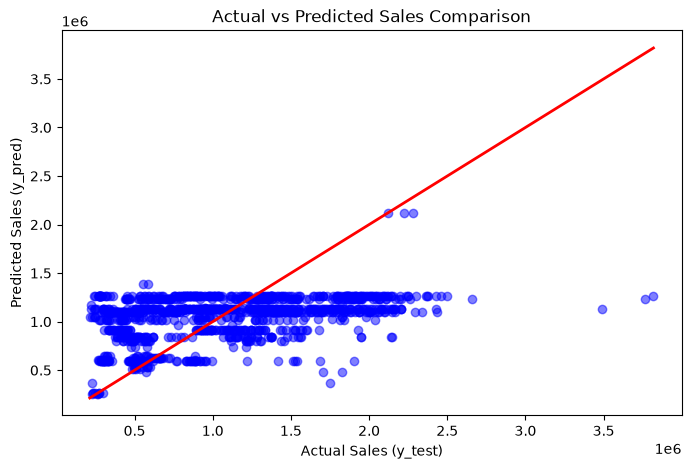

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
# Plotting actual vs predicted values
plt.scatter(y_test, y_pred, color='blue', alpha=0.5)
# Drawing a perfect match reference line
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linewidth=2)

plt.xlabel("Actual Sales (y_test)")
plt.ylabel("Predicted Sales (y_pred)")
plt.title("Actual vs Predicted Sales Comparison")
plt.show()

In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import pandas as pd

# Formatting normal numbers-ah mathadhum (e+06 pogum)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

# 1. Advanced Model (Random Forest) ah train seigirom
rf_model = RandomForestRegressor(n_estimators=200, max_depth=12, random_state=42)
rf_model.fit(X_train, y_train)

# 2. Pudhiya prediction answers uruvagiradhu
y_pred_new = rf_model.predict(X_test)

# 3. Ippo accuracy matrum table-ah print seigirom
print(f"New Improved R2 Score: {r2_score(y_test, y_pred_new):.4f}\n")

comparison_table = pd.DataFrame({
    'Actual Values (y_test)': y_test.values,
    'New Predicted Values (y_pred)': y_pred_new
})
print(comparison_table.head(10))


New Improved R2 Score: 0.2668

   Actual Values (y_test)  New Predicted Values (y_pred)
0              1138800.32                     1112836.10
1              1304850.67                     1132977.56
2              1769296.25                     1041013.52
3              1077640.13                     1097772.18
4               428851.99                      707095.99
5              1004523.59                      986751.68
6              1523410.71                      763668.04
7              1014898.78                      981291.39
8              1955896.59                     1513339.62
9               958667.23                     1001595.72
